# Task 3 held-out evaluation

This notebook reads the frozen protocol and the saved test predictions for Random Forest, XGBoost and TimesNet. Every table and figure is rebuilt from the saved per-case predictions; nothing is refitted or tuned here.

The release has unresolved recording reviews, so all numbers are provisional. Random Forest and XGBoost seed-42 test scores were already seen in earlier work; the protocol lists that exposure.

Command-line equivalent: `uv run python -m clauseguard.cli.final_evaluation evaluate --release-dir data/scenarios/release --output-dir artifacts/experiments/task-3-8-final-evaluation-2026-11-05 --allow-exploratory`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from clauseguard.baselines.final_evaluation import (
    CLASS_NAMES, MODELS, load_protocol, predict_test, write_report,
)
from clauseguard.datasets.scenarios import ScenarioDataset

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data/scenarios/release/release.json").exists())
os.chdir(ROOT)

OUTPUT_DIR = Path("artifacts/experiments/task-3-8-final-evaluation-2026-11-05")
FIGURES = OUTPUT_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
DATASET = ScenarioDataset(Path("data/scenarios/release"), allow_exploratory=True)
PROTOCOL = load_protocol(OUTPUT_DIR)
RUNS = predict_test(DATASET, OUTPUT_DIR, allow_exploratory=True)  # reuses the saved test runs
TABLES = write_report(DATASET, OUTPUT_DIR, RUNS)["tables"]
print({"protocol": PROTOCOL["protocol_sha256"][:12], "status": PROTOCOL["evaluation_status"],
       "dev comparators": PROTOCOL["dev_comparators"], "text": PROTOCOL["text"]["status"]})

{'protocol': '458c1e613776', 'status': 'provisional_exploratory', 'dev comparators': {'category': 'random_forest', 'detection': 'xgboost'}, 'text': 'blocked'}


## Detection

Normal windows dominate the test set, so the normal-majority reference is shown next to the models. Macro-F1, missed faults and false alarms matter more than accuracy.

,model,seed,macro_f1,accuracy,recall,false_alarms,missed_faults,failed_predictions
0,random_forest,42,0.663,0.961,0.210,1,244,0
1,random_forest,43,0.710,0.965,0.282,1,222,0
2,random_forest,44,0.647,0.960,0.188,1,251,0
3,timesnet,42,0.674,0.897,0.715,564,88,0
4,timesnet,43,0.604,0.849,0.641,844,111,0
5,timesnet,44,0.635,0.868,0.709,745,90,0
6,xgboost,42,0.925,0.987,0.777,11,69,0
7,xgboost,43,0.925,0.987,0.777,11,69,0
8,xgboost,44,0.925,0.987,0.777,11,69,0
9,normal_majority,,0.487,0.951,0.000,0,309,0


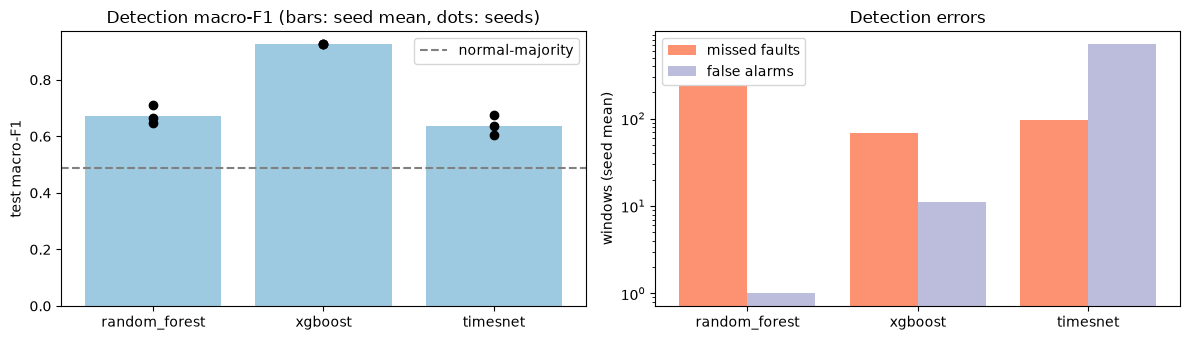

In [2]:
detection = pd.DataFrame(TABLES["detection"] + TABLES["detection_reference"])
display(detection[["model", "seed", "macro_f1", "accuracy", "recall", "false_alarms",
                   "missed_faults", "failed_predictions"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
reference = TABLES["detection_reference"][0]
for index, model in enumerate(MODELS):
    rows = detection[detection.model == model]
    axes[0].scatter([index] * len(rows), rows.macro_f1, color="black", zorder=3)
    axes[0].bar(index, rows.macro_f1.mean(), color="#9ecae1")
    axes[1].bar(index - 0.2, rows.missed_faults.mean(), width=0.4, color="#fc9272",
                label="missed faults" if index == 0 else None)
    axes[1].bar(index + 0.2, rows.false_alarms.mean(), width=0.4, color="#bcbddc",
                label="false alarms" if index == 0 else None)
axes[0].axhline(reference["macro_f1"], color="grey", linestyle="--", label="normal-majority")
axes[0].set(xticks=range(len(MODELS)), xticklabels=MODELS, ylabel="test macro-F1",
            title="Detection macro-F1 (bars: seed mean, dots: seeds)")
axes[0].legend()
axes[1].set(xticks=range(len(MODELS)), xticklabels=MODELS, ylabel="windows (seed mean)",
            title="Detection errors", yscale="log")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "detection.png", dpi=150)

## Fault category

Category scores use known synthetic faults only. The test set has two recording groups, so a single recording can move a class score a lot.

,model,seed,windows,failed_predictions,macro_f1,accuracy
0,random_forest,42,216,0,0.224,0.310
1,random_forest,43,216,0,0.229,0.315
2,random_forest,44,216,0,0.233,0.310
3,timesnet,42,216,0,0.030,0.060
4,timesnet,43,216,0,0.156,0.366
5,timesnet,44,216,0,0.229,0.398
6,xgboost,42,216,0,0.352,0.495
7,xgboost,43,216,0,0.352,0.495
8,xgboost,44,216,0,0.352,0.495


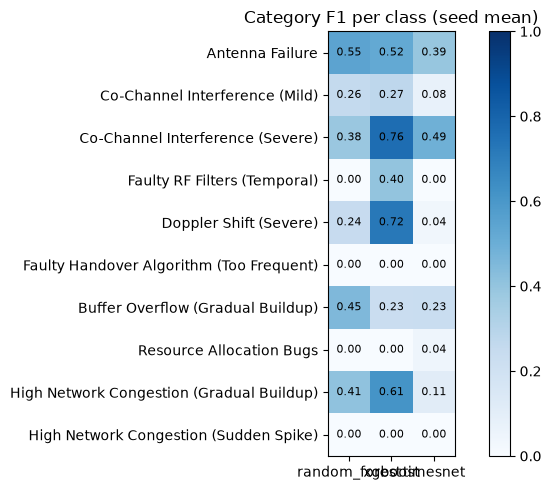

In [3]:
per_class = pd.DataFrame(TABLES["per_class"])
category = (per_class[per_class.task == "category"]
            .groupby(["name", "model"]).f1.mean().unstack()[list(MODELS)]
            .reindex(CLASS_NAMES["category"]))
display(pd.DataFrame(TABLES["category"]).round(3))
fig, axis = plt.subplots(figsize=(7, 5))
image = axis.imshow(category.values, cmap="Blues", vmin=0, vmax=1)
axis.set(xticks=range(len(MODELS)), xticklabels=MODELS, yticks=range(len(category)),
         yticklabels=category.index, title="Category F1 per class (seed mean)")
for (row, col), value in np.ndenumerate(category.values):
    axis.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image)
fig.tight_layout()
fig.savefig(FIGURES / "category_f1.png", dpi=150)

## Combined diagnosis

The detector decides first; windows it calls abnormal take the category from the same model and seed. Normal windows that the detector wrongly flags count as errors. Jamming is scored only in detection.

,model,seed,windows,failed_predictions,macro_f1,accuracy
0,random_forest,42,6228,1,0.203,0.969
1,random_forest,43,6228,1,0.191,0.969
2,random_forest,44,6228,1,0.212,0.969
3,xgboost,42,6228,11,0.322,0.976
4,xgboost,43,6228,11,0.322,0.976
5,xgboost,44,6228,11,0.322,0.976
6,timesnet,42,6228,564,0.115,0.877
7,timesnet,43,6228,844,0.236,0.841
8,timesnet,44,6228,745,0.280,0.857


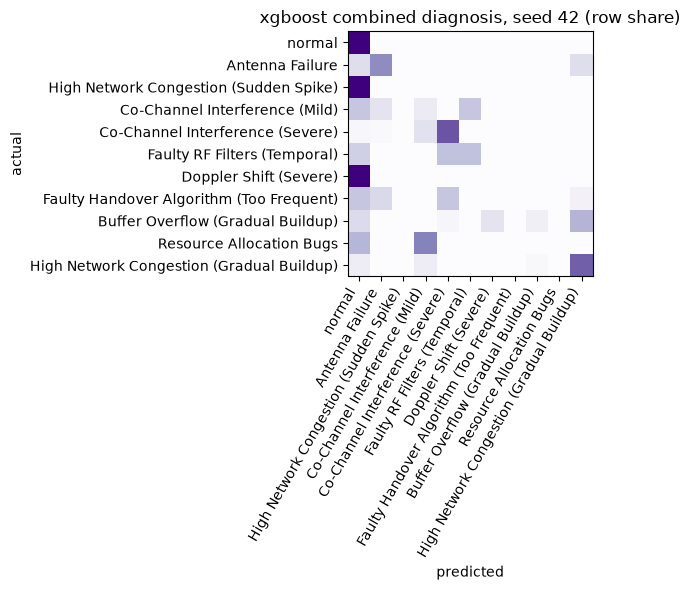

In [4]:
display(pd.DataFrame(TABLES["diagnosis"]).round(3))
comparator = PROTOCOL["dev_comparators"]["detection"]
confusion = json.loads((OUTPUT_DIR / "confusion.json").read_text())
matrix = pd.DataFrame(confusion[f"{comparator}/diagnosis/seed-42"]).T
matrix = matrix.drop(columns="missing").astype(int)
names = [CLASS_NAMES["diagnosis"][int(label)] for label in matrix.index]
rates = matrix.div(matrix.sum(axis=1).where(lambda total: total > 0, 1), axis=0)
fig, axis = plt.subplots(figsize=(8, 6))
axis.imshow(rates.values, cmap="Purples", vmin=0, vmax=1)
axis.set(xticks=range(len(names)), xticklabels=names, yticks=range(len(names)), yticklabels=names,
         xlabel="predicted", ylabel="actual",
         title=f"{comparator} combined diagnosis, seed 42 (row share)")
plt.setp(axis.get_xticklabels(), rotation=60, ha="right")
fig.tight_layout()
fig.savefig(FIGURES / "diagnosis_confusion.png", dpi=150)

## Detection errors by origin

Missed faults and false alarms split by where each window came from. Jamming is real interference; the other fault labels are synthetic.

In [5]:
errors = pd.DataFrame(TABLES["errors_by_origin"])
display(errors.groupby(["origin", "rca_label", "model"])[["windows", "missed_faults", "false_alarms"]]
        .mean().unstack("model").round(1))
print((OUTPUT_DIR / "report.md").resolve())

windows           \
model                                               random_forest timesnet   
origin    rca_label                                                          
normal    normal                                           6012.0   6012.0   
real      Jamming                                            93.0     93.0   
synthetic Antenna Failure                                     9.0      9.0   
          Buffer Overflow (Gradual Buildup)                  37.0     37.0   
          Co-Channel Interference (Mild)                     21.0     21.0   
          Co-Channel Interference (Severe)                   50.0     50.0   
          Doppler Shift (Severe)                             18.0     18.0   
          Faulty Handover Algorithm (Too Frequent)           12.0     12.0   
          Faulty RF Filters (Temporal)                       17.0     17.0   
          High Network Congestion (Gradual Buildup)          31.0     31.0   
          High Network Congestion (Sudden Spike)             11.0     11.0   
          Resource Allocation Bugs                           10.0     10.0   

                                                            missed_faults  \
model                                               xgboost random_forest   
origin    rca_label                                                         
normal    normal                                     6012.0           0.0   
real      Jamming                                      93.0          89.0   
synthetic Antenna Failure                               9.0           2.7   
          Buffer Overflow (Gradual Buildup)            37.0          19.3   
          Co-Channel Interference (Mild)               21.0          14.0   
          Co-Channel Interference (Severe)             50.0          43.7   
          Doppler Shift (Severe)                       18.0          18.0   
          Faulty Handover Algorithm (Too Frequent)     12.0          10.0   
          Faulty RF Filters (Temporal)                 17.0          13.7   
          High Network Congestion (Gradual Buildup)    31.0           7.7   
          High Network Congestion (Sudden Spike)       11.0          11.0   
          Resource Allocation Bugs                     10.0          10.0   

                                                                      \
model                                               timesnet xgboost   
origin    rca_label                                                    
normal    normal                                         0.0     0.0   
real      Jamming                                        7.7     3.0   
synthetic Antenna Failure                                2.0     2.0   
          Buffer Overflow (Gradual Buildup)              9.0     9.0   
          Co-Channel Interference (Mild)                12.3     7.0   
          Co-Channel Interference (Severe)               4.7     2.0   
          Doppler Shift (Severe)                        18.0    18.0   
          Faulty Handover Algorithm (Too Frequent)       4.0     4.0   
          Faulty RF Filters (Temporal)                   7.7     5.0   
          High Network Congestion (Gradual Buildup)     10.0     4.0   
          High Network Congestion (Sudden Spike)        11.0    11.0   
          Resource Allocation Bugs                      10.0     4.0   

                                                     false_alarms           \
model                                               random_forest timesnet   
origin    rca_label                                                          
normal    normal                                              1.0    717.7   
real      Jamming                                             0.0      0.0   
synthetic Antenna Failure                                     0.0      0.0   
          Buffer Overflow (Gradual Buildup)                   0.0      0.0   
          Co-Channel Interference (Mild)                      0.0      0.0   
          Co-Channel Inter

artifacts/experiments/task-3-8-final-evaluation/report.md
